# 09 Model comparison

**Goal:** compare all models with the same code, at window level and at bump level, and choose the model to fine-tune.

**Bump level** (what a road owner cares about):
- A bump pass = a group of consecutive bump windows in one drive.
- A bump pass is **found** if at least one of its windows is predicted as bump.
- A predicted bump window is a **real false alarm** only if it is more than 2 windows (10 m) away from every real bump window. Alarms right next to a bump are counted as "close enough".

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score

files = {
    "Random forest": "predictions/predictions_rf.csv",
    "MiniRocket": "predictions/predictions_minirocket.csv",
    "1D CNN": "predictions/predictions_cnn.csv",
    "Arsenal": "predictions/predictions_arsenal.csv",
}

predictions = {}
for name, path in files.items():
    predictions[name] = pd.read_csv(path)
    print(name, predictions[name].shape)

Random forest (2728, 6)
MiniRocket (2729, 6)
1D CNN (2729, 6)
Arsenal (2729, 6)


In [2]:
rf = predictions["Random forest"]
ars = predictions["Arsenal"]

# Combine Arsenal's windows with the RF's windows, matched on drive + window number.
check = ars.merge(rf[["drive", "window"]], on=["drive", "window"], how="left", indicator=True)

# "left_only" = the window exists in Arsenal's file but not in the RF's.
missing = check[check["_merge"] == "left_only"]
print(missing[["road", "is_bump"]])
print("Position in its drive:", (ars[ars["drive"] == missing["drive"].iloc[0]]["window"] < missing["window"].iloc[0]).mean().round(2))

                  road  is_bump
2630  sinetänsalmentie        0
Position in its drive: 0.0


Note: the RF predictions have 2728 windows instead of 2729. The missing one is the first window of one sinetänsalmentie drive (a no bump window at the edge of the drive), which the RF pipeline in 05 does not keep. It cannot change the bump detection results and changes false alarm counts by at most 1, so the comparison stays fair.

In [3]:
def window_level(p):
    return {
        "recall": recall_score(p["is_bump"], p["pred"]),
        "precision": precision_score(p["is_bump"], p["pred"]),
        "f1": f1_score(p["is_bump"], p["pred"]),
        "auc": roc_auc_score(p["is_bump"], p["prob"]),
    }

In [4]:
def bump_level(p):
    bumps_total = 0
    bumps_found = 0
    real_false_alarms = 0

    for drive in p["drive"].unique():
        # This drive's windows, in road order.
        d = p[p["drive"] == drive].sort_values("window")

        # --- 1. Group the bump windows into bump passes ---
        bump_windows = d[d["is_bump"] == 1]["window"].tolist()
        bumps = []
        for w in bump_windows:
            if len(bumps) > 0 and w - bumps[-1][-1] == 1:
                bumps[-1].append(w)     # next to the previous bump window -> same bump
            else:
                bumps.append([w])       # a gap -> a new bump starts

        # --- 2. Was each bump found? ---
        flagged = d[d["pred"] == 1]["window"].tolist()
        for bump in bumps:
            bumps_total = bumps_total + 1
            for w in bump:
                if w in flagged:
                    bumps_found = bumps_found + 1
                    break

        # --- 3. Real false alarms ---
        alarms = d[(d["pred"] == 1) & (d["is_bump"] == 0)]["window"].tolist()
        for a in alarms:
            near_a_bump = False
            for b in bump_windows:
                if abs(a - b) <= 2:
                    near_a_bump = True
            if not near_a_bump:
                real_false_alarms = real_false_alarms + 1

    km = len(p) * 5 / 1000
    return {
        "bumps_total": bumps_total,
        "bumps_found": bumps_found,
        "detection_rate": bumps_found / bumps_total,
        "real_false_alarms": real_false_alarms,
        "false_alarms_per_km": real_false_alarms / km,
    }

In [5]:
rows = []
for name, p in predictions.items():
    row = {"model": name}
    row.update(window_level(p))
    row.update(bump_level(p))
    rows.append(row)

comparison = pd.DataFrame(rows)
print(comparison.round(2).to_string(index=False))

        model  recall  precision   f1  auc  bumps_total  bumps_found  detection_rate  real_false_alarms  false_alarms_per_km
Random forest    0.39       0.52 0.45 0.71           48           46            0.96                178                13.05
   MiniRocket    0.49       0.34 0.40 0.66           48           47            0.98                449                32.91
       1D CNN    0.43       0.36 0.39 0.61           48           46            0.96                386                28.29
      Arsenal    0.36       0.55 0.44 0.66           48           39            0.81                141                10.33


### Comparing at the same detection rate

At the default threshold (0.5) the models make different trade-offs. Here we move the threshold from 0.05 to 0.95 and measure bumps found and false alarms for each value. (MiniRocket is left out: its scores are not probabilities between 0 and 1.)

In [6]:
import matplotlib.pyplot as plt

thresholds = np.arange(0.05, 1.0, 0.05)
curve_rows = []

for name in ["Random forest", "1D CNN", "Arsenal"]:
    p = predictions[name].copy()
    for t in thresholds:
        # New predictions: bump if the probability is at least t.
        p["pred"] = (p["prob"] >= t).astype(int)
        row = bump_level(p)
        row["model"] = name
        row["threshold"] = t
        curve_rows.append(row)

curve = pd.DataFrame(curve_rows)

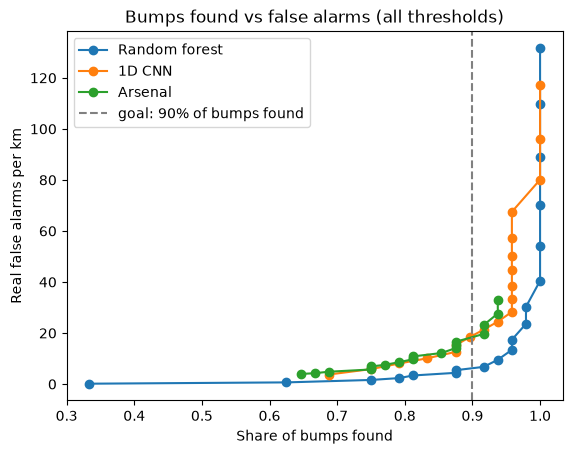

In [7]:
for name in curve["model"].unique():
    c = curve[curve["model"] == name]
    plt.plot(c["detection_rate"], c["false_alarms_per_km"], marker="o", label=name)

plt.axvline(0.9, color="grey", linestyle="--", label="goal: 90% of bumps found")
plt.xlabel("Share of bumps found")
plt.ylabel("Real false alarms per km")
plt.title("Bumps found vs false alarms (all thresholds)")
plt.legend()
plt.show()

In [8]:
ok = curve[curve["detection_rate"] >= 0.9]
best = ok.sort_values("false_alarms_per_km").groupby("model").head(1)
print(best[["model", "threshold", "bumps_found", "detection_rate", "real_false_alarms", "false_alarms_per_km"]].round(2).to_string(index=False))

        model  threshold  bumps_found  detection_rate  real_false_alarms  false_alarms_per_km
Random forest        0.6           44            0.92                 92                 6.74
      Arsenal        0.2           44            0.92                268                19.64
       1D CNN        0.6           44            0.92                291                21.33


In [9]:
from sklearn.metrics import accuracy_score

p = predictions["Random forest"]
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p["prob"] >= t).astype(int)
    print("threshold", t, "→ window accuracy:", round(accuracy_score(p["is_bump"], pred), 3))

print("always 'no bump' would get:", round(1 - p["is_bump"].mean(), 3))

threshold 0.3 → window accuracy: 0.706
threshold 0.4 → window accuracy: 0.777
threshold 0.5 → window accuracy: 0.815
threshold 0.6 → window accuracy: 0.835
threshold 0.7 → window accuracy: 0.839
always 'no bump' would get: 0.81


## Conclusion of 09: model choice

### What we compared
Five models from three families of time series classification, all on **the same 5 m windows**, **the same leave-one-road-out split** (train on two roads, test on the third) and **the same evaluation code**:

| Family | Model | Input |
|---|---|---|
| Feature-based | **Random forest** | 7 speed-corrected features per window (std of each sensor ÷ the drive's normal level) |
| Kernel-based | MiniRocket, Arsenal | raw windows: 7 sensor channels × 100 points |
| Deep learning | 1D CNN, LSTM | raw windows: 7 sensor channels × 100 points |

### Step 1: window level at default settings
| Model | Avg F1 | Avg AUC |
|---|---|---|
| Random forest | 0.44 | **0.76** |
| MiniRocket | 0.40 | 0.74 |
| 1D CNN (5 seeds) | 0.40 | 0.70 |
| LSTM (3 seeds) | 0.35 | 0.69 |
| Arsenal | **0.49** | 0.75 |

At this level Arsenal looked best. But window F1 depends on each model's **default threshold** (its "sensitivity"), and it grades every 5 m window separately, even the calm flat top of a long heave.

### Step 2: bump level, which matches the goal
Goal: **find the frost heaves on a road the model has never seen, with as few false alarms as possible.** A bump counts as found if at least one of its windows is flagged; an alarm counts as false only if it is more than 10 m from any bump.

**At default settings:**

| Model | Bumps found | Real false alarms per km |
|---|---|---|
| **Random forest** | **46/48 (96%)** | 13.1 |
| MiniRocket | 47/48 (98%) | 32.9 |
| 1D CNN | 46/48 (96%) | 28.3 |
| Arsenal | 39/48 (81%) | 10.3 |

**At the same sensitivity (every model set to find at least 90% of the bumps):**

| Model | Bumps found | Real false alarms per km |
|---|---|---|
| **Random forest** | 44/48 (92%) | **6.7** |
| Arsenal | 44/48 (92%) | 19.6 |
| 1D CNN | 44/48 (92%) | 21.3 |

- At the same sensitivity, the random forest gives **about 3× fewer false alarms** than Arsenal and the CNN.
- In the plot `figures/tradeoff_bump_level.png`, the random forest's line is the lowest **at every sensitivity**, and it is the only model that can find **all** bumps. Arsenal cannot find more than ~94% at any setting.
- Arsenal's better window F1 came from its more careful default threshold, not from better detection.

### Step 3: what makes the random forest strong (05b)
With the **same split and the same random forest**, only the input changed:

| | Jeremy's starter pipeline (raw 40-row panels) | Our pipeline (5 m windows, speed-corrected features) |
|---|---|---|
| Kaittiaisentie: accuracy | 0.95 | 0.88 |
| Kaittiaisentie: bumps found | **0%** | **80%** |
| m792: bump F1 | 0.44 | **0.63** |

The random forest is only strong with our features. Its performance comes from the **feature engineering**: windows by distance, and shaking measured relative to each drive's normal level (which removed the speed-caused false alarms in 05).

### Decision: the random forest is the model we fine-tune

1. **Best result for the goal:** the fewest false alarms at every share of bumps found (6.7 per km at 92% found).
2. **Suits our small dataset:** only 3 roads and 48 bump passes. The CNN and LSTM overfit within a few epochs; the random forest (many trees voting) is robust.
3. **Domain knowledge in the features:** "how much stronger than normal did the car shake" is exactly what a bump causes, independent of speed.
4. **A recognised time series method:** the feature-based approach (summarise each window, then classify), also offered by sktime (e.g. `SummaryClassifier`, a random forest by default).
5. **Explainable:** feature importance shows which sensor reactions the model uses.
6. **Fast:** trains in seconds, which makes tuning and the dashboard practical.

### Limitations
- The features were designed by us after exploring all the data, so the random forest got more human input than the other models.
- The thresholds in the bump-level comparison were chosen using the test results (slightly optimistic). In 10 the threshold is chosen fairly.
- Only 3 roads: with much more data, the models that learn by themselves might catch up.
- Each window is judged without context from its neighbours, so the calm flat top of long heaves is often missed at window level. This is the first experiment in 10.